# Discrete-Time Euler Simulator

In [1]:
from math import sin, cos, pi
import numpy as np
import matplotlib.pyplot as plt

Constantes e equações governantes em:

https://ctms.engin.umich.edu/CTMS/index.php?example=InvertedPendulum&section=SystemModeling

In [2]:
# Aceleração gravitacional (m/s^2)
g = 9.8

# Massa do carrinho (kg)
m_cart = 0.5

# Massa do pêndulo (kg)
m_pend = 0.2

# Coeficiente de atrito do carrinho (N*s/m)
b = 0.1

# Distância do ponto de fixação do pêndulo até o seu centro de massa (m)
l = 0.3

# Momento de inércia de massa do pêndulo (kg.m^2) = 1/12 * mL^2
i = 0.006

Seguindo as equações governantes (3) e (6)

$$
(M + m)\ddot{x} + b\dot{x} + ml\ddot{\theta}\cos{\theta} - ml\dot{\theta}^2\sin{\theta} = u
$$

$$
(I + ml^2)\ddot{\theta} + mgl\sin{\theta} = -ml\ddot{x}\cos{\theta}
$$

resolve-se o sistema de equações de forma a encontrar $\ddot{x}$ e $\ddot{\theta}$ em função de $x$, $\theta$, $\dot{x}$, $\dot{\theta}$ e $u$.

$$
\ddot{x} = \frac{-(I + ml^2)b\dot{x} + (I + ml^2)ml\dot{\theta}^2\sin{\theta} + (ml)^2g\cos{\theta}\sin{\theta} + (I + ml^2)u}{(M + m)(I + ml^2) - (ml\cos{\theta})^2}
$$

$$
\ddot{\theta} = \frac{ ml\cos{\theta}b\dot{x} - (ml)^2\dot{\theta}^2\cos{\theta}\sin{\theta} - (M + m)mgl\sin{\theta} - mlu\cos{\theta}}{(M + m)(I + ml^2) - (ml\cos{\theta})^2}
$$

In [3]:
def ddot_x_def(x, dot_x, theta, dot_theta, u):
    "Define ddot_x a partir de x, dot_x, theta, dot_theta e u."

    return (- (i + m_pend * l**2) * b * dot_x
            + (i + m_pend * l**2) * m_pend * l * dot_theta**2 * sin(theta)
            + (m_pend * l)**2 * g * cos(theta) * sin(theta)
            + (i + m_pend * l**2) * u) / ((m_cart + m_pend) * (i + m_pend * l**2) - (m_pend * l * cos(theta))**2)

def ddot_theta_def(x, dot_x, theta, dot_theta, u):
    "Define ddot_theta a partir de x, dot_x, theta, dot_theta e u."
    
    return (m_pend * l * cos(theta) * b * dot_x
            - (m_pend * l)**2 * dot_theta**2 * cos(theta) * sin(theta)
            - (m_cart + m_pend) * m_pend * g * l * sin(theta)
            - m_pend * l * u * cos(theta)) / ((m_cart + m_pend) * (i + m_pend * l**2) - (m_pend * l * cos(theta))**2)

Assim, é possível definir as derivadas das variáveis de estado seguindo o Método de Euler em uma representação do sistema em tempo discreto

$$
s(k + 1) = T_sf(s(k), u(k)) + s(k)
$$

sendo $T_s$ o período de amostragem e $f(s(k), u(k)) = \dot{s}$.

$$
x(k + 1) = T_s\dot{x}(k) + x(k)
$$

$$
\dot{x}(k + 1) = T_s[\frac{-(I + ml^2)b\dot{x}(k) + (I + ml^2)ml\dot{\theta}(k)^2\sin{\theta}(k) + (ml)^2g\cos{\theta(k)}\sin{\theta(k)} + (I + ml^2)u(k)}{(M + m)(I + ml^2) - (ml\cos{\theta(k)})^2}] + \dot{x}(k)
$$

$$
\theta(k + 1) = T_s\dot{\theta}(k) + \theta(k)
$$

$$
\dot{\theta}(k + 1) = T_s[\frac{ ml\cos{\theta(k)}b\dot{x}(k) - (ml)^2\dot{\theta}(k)^2\cos{\theta(k)}\sin{\theta(k)} - (M + m)mgl\sin{\theta(k)} - mlu\cos{\theta(k)}}{(M + m)(I + ml^2) - (ml\cos{\theta(k)})^2}] + \dot{\theta}(k)
$$

In [4]:
# Período de amostragem
t_s = 5e-4

def step(s, u, t_s):
    "Define s(k+1) a partir de s(k) e u."

    # x(k), dot_x(k), theta(k), dot_theta(k)
    x, dot_x , theta, dot_theta = s

    ddot_x = ddot_x_def(x, dot_x, theta, dot_theta, u)
    ddot_theta = ddot_theta_def(x, dot_x, theta, dot_theta, u)

    return np.array([
        t_s * dot_x + x,                # x(k+1)
        t_s * ddot_x + dot_x,           # dot_x(k+1)
        t_s * dot_theta + theta,        # theta(k+1)
        t_s * ddot_theta + dot_theta    # dot_theta(k+1)
    ])

# Vetor de estados iniciais do sistema [x, dx/dt, phi, dphi/dt]
s0 = [0, 0, pi, 0]

# Função lambda que define a entrada u
u = lambda t: 1 if t < 0.1 else 0  

# Tempo de execução
t_exec = 0.5

In [5]:
def simulate(s0, u, t_s, t_exec):
    n = int(t_exec / t_s)
    t = np.arange(n + 1) * t_s
    u_t = np.array([u(i) for i in t])

    s = np.zeros((n + 1, 4))
    s[0] = s0
    for k in range(n):
        s[k+1] = step(s[k], u_t[k], t_s)
    return t, s, u_t

t, s, u_t = simulate(s0, u, t_s, t_exec)

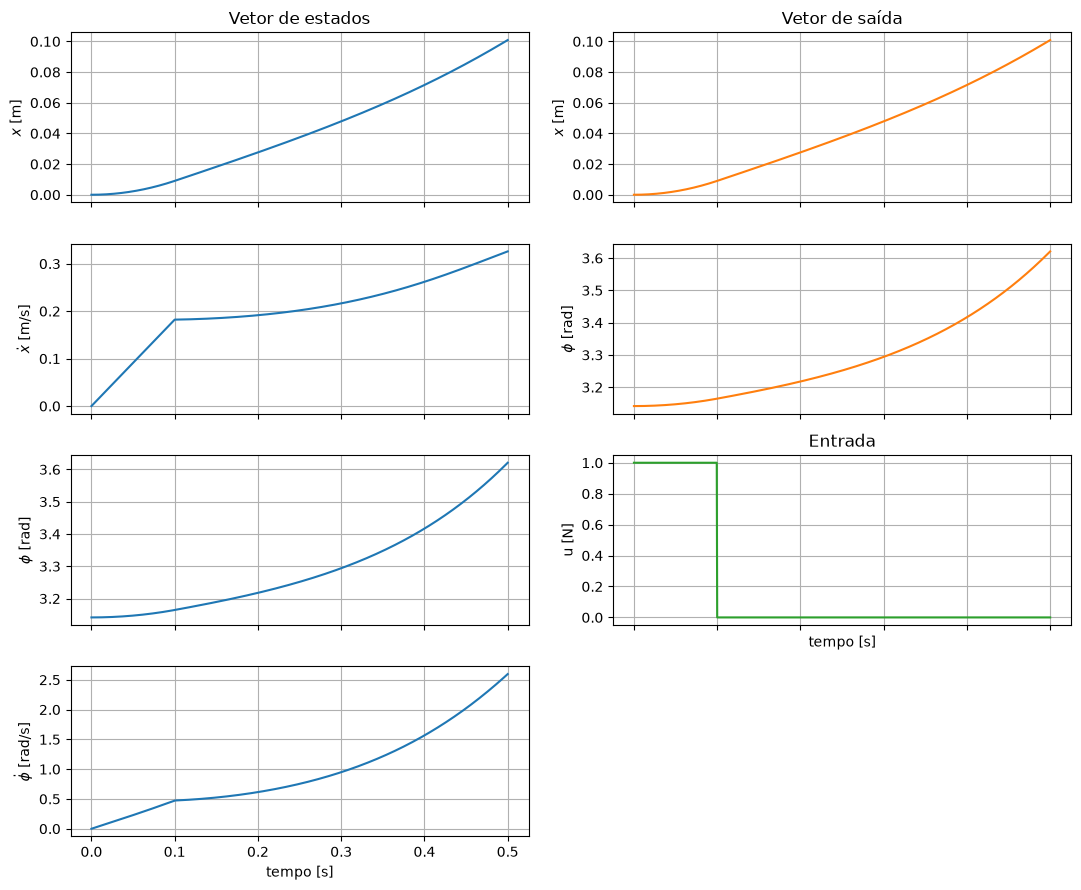

In [6]:
nomes_estados = [r"$x$ [m]", r"$\dot{x}$ [m/s]", r"$\phi$ [rad]", r"$\dot{\phi}$ [rad/s]"]
nomes_saidas  = [r"$x$ [m]", r"$\phi$ [rad]"]

y = s[:, [0, 2]]   # saídas: x e phi

fig, axs = plt.subplots(4, 2, figsize=(11, 9), sharex=True)

# Coluna da esquerda: vetor de estados
for i in range(4):
    axs[i, 0].plot(t, s[:, i])
    axs[i, 0].set_ylabel(nomes_estados[i])
    axs[i, 0].grid(True)
axs[0, 0].set_title("Vetor de estados")

# Coluna da direita: vetor de saída + entrada
for i in range(2):
    axs[i, 1].plot(t, y[:, i], color="C1")
    axs[i, 1].set_ylabel(nomes_saidas[i])
    axs[i, 1].grid(True)
axs[0, 1].set_title("Vetor de saída")

axs[2, 1].plot(t, u_t, color="C2")
axs[2, 1].set_ylabel("u [N]")
axs[2, 1].set_title("Entrada")
axs[2, 1].grid(True)
axs[3, 1].axis("off")

axs[3, 0].set_xlabel("tempo [s]")
axs[2, 1].set_xlabel("tempo [s]")
plt.tight_layout()
plt.show()